# Notebook 1 of 3 — Training (manual §5.4 step 3: "Run training in one notebook")

**Settings:** Accelerator **GPU T4 x2**, Internet **On**. Start it with **Save Version → Save & Run All (Commit)**.

| Section | Manual task |
|---|---|
| Setup: clone, install, GPUs, versions, adapter tests | Task 1 (§7), §4.2 |
| Data preparation (SFT 30k/1k, HH 15k/1k, UltraFeedback 15k/1k) | §6.2–6.3 |
| SFT on Qwen2.5-0.5B | Task 3 (§9) |
| From-scratch DPO on HH-RLHF | Task 4 (§10) |
| From-scratch DPO on UltraFeedback | Task 4 (§10) |
| TRL DPOTrainer + LoRA persona run | Task 5 (§11) |

All checkpoints, `metrics.jsonl` files, plots and zips are written under
`/kaggle/working/cs5326-PA2-27100015/outputs/` (manual §5.5). When the run completes, this saved version is
attached as the input of Notebook 2.

## Task 1 — Repository and Kaggle setup

In [1]:
# Manual section 7.1: clone the repository in Kaggle (Notebook settings: Internet ON).
import os
REPO_URL = "https://github.com/mahamasiff/cs5326-PA2-27100015.git"
REPO_DIR = "/kaggle/working/cs5326-PA2-27100015"
if not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}
!git log --oneline -1

/kaggle/working/cs5326-PA2-27100015
96451ff (HEAD -> main, origin/main, origin/HEAD) Show subprocess output in notebooks; relax GPU smoke-test check


In [2]:
import subprocess
def sh(cmd):
    """Run a shell command, show its output in this cell, and stop the notebook if it fails."""
    print("$", cmd, flush=True)
    proc = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    if proc.wait() != 0:
        raise RuntimeError(f"command failed with exit code {proc.returncode} (see output above): {cmd}")

In [3]:
# Manual sections 5.2 and 7.2: install dependencies without reinstalling PyTorch.
# peft/trl are added for the Task 5 LoRA run; torchao is removed to avoid the known PEFT conflict.
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest "peft>=0.11.0" "trl>=0.24,<0.30"
!python -m pip install -q -e . --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 531.0/531.0 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 87.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) 

In [4]:
# Manual sections 5.1, 7.3 and 7.4: confirm two T4 GPUs and print package versions.
!nvidia-smi
import torch, transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
assert torch.cuda.device_count() == 2, "Select the GPU T4 x2 accelerator"

Sat Oct 17 11:25:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
# Manual §4.2: public adapter smoke tests (plus our own edge-case and judging tests).
sh("PYTHONPATH=. python -m pytest -q tests/")

$ PYTHONPATH=. python -m pytest -q tests/
.......................                                                  [100%]
23 passed in 5.30s


## Data preparation (§6.2–6.3, seed 42)

In [6]:
# UltraChat single-turn SFT data, single-turn HH-RLHF pairs, single-turn UltraFeedback pairs.
# Writes data/processed/*.jsonl and data/manifests/*_ids.json + *_stats.json (filter counts for the report).
sh("python scripts/prepare_data.py --out_dir data/processed --which sft hh uf")
!wc -l data/processed/*.jsonl
!cat data/manifests/*_stats.json

$ python scripts/prepare_data.py --out_dir data/processed --which sft hh uf

Generating train_sft split: 100%|██████████| 207865/207865 [00:04<00:00, 51606.77 examples/s]

Generating test_sft split: 100%|██████████| 23110/23110 [00:00<00:00, 55296.26 examples/s]

Generating train_gen split: 100%|██████████| 256032/256032 [00:03<00:00, 70187.22 examples/s]

Generating test_gen split: 100%|██████████| 28304/28304 [00:00<00:00, 69918.65 examples/s]
[sft] train: {'hf_split': 'train_sft', 'available': 207865, 'requested': 30000, 'empty': 1, 'scanned': 30001, 'kept': 30000}
[sft] val: {'hf_split': 'test_sft', 'available': 23110, 'requested': 1000, 'scanned': 1000, 'kept': 1000}

Generating train split: 100%|██████████| 160800/160800 [00:02<00:00, 67667.30 examples/s]

Generating test split: 100%|██████████| 8552/8552 [00:00<00:00, 67940.29 examples/s]
[hh] train: {'hf_split': 'train', 'available': 160800, 'requested': 15000, 'multi_turn': 34094, 'empty': 13, 'identical_responses': 9, 'scanne

In [7]:
# One-minute end-to-end check with a tiny random model before the long runs.
sh("python scripts/smoke_train.py --work_dir /tmp/pa2_smoke")

$ python scripts/smoke_train.py --work_dir /tmp/pa2_smoke
The tokenizer you are loading from '/tmp/pa2_smoke/tiny_base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
[sft] train=16 val=8 optimizer_steps=4 warmup=0
{"split": "train", "step": 1, "elapsed_s": 1.2, "loss": 11.854609966278076, "lr": 0.0008535533905932737, "grad_norm": 4.183220386505127, "epoch": 0.0, "skipped_steps": 0.0}
{"split": "train", "step": 2, "elapsed_s": 1.3, "loss": 11.568029403686523, "lr": 0.0005, "grad_norm": 3.679448366165161, "epoch": 0.0, "skipped_steps": 0.0}
{"split": "val", "step": 2, "elapsed_s": 1.3, "loss": 11.424388885498047, "ppl": 91526.96300436775, "is_best": 1.0}
{"split": "train", "step": 3, "elapsed_s": 1.6, "loss"

## Task 3 — Supervised fine-tuning (`configs/sft.yaml`, guide configuration §9.2)

In [8]:
sh("python scripts/train_sft.py --config configs/sft.yaml")

$ python scripts/train_sft.py --config configs/sft.yaml
`torch_dtype` is deprecated! Use `dtype` instead!
[sft] train=30000 val=1000 optimizer_steps=938 warmup=28
{"split": "train", "step": 1, "elapsed_s": 9.3, "loss": 1.21961185708642, "lr": 1.4285714285714286e-06, "grad_norm": 5.026761531829834, "epoch": 0.0, "skipped_steps": 0.0}
{"split": "train", "step": 10, "elapsed_s": 52.4, "loss": 1.458047895381848, "lr": 7.857142857142858e-06, "grad_norm": 5.359160900115967, "epoch": 0.0, "skipped_steps": 1.0}
{"split": "train", "step": 20, "elapsed_s": 103.8, "loss": 1.3650808155536651, "lr": 1.5000000000000002e-05, "grad_norm": 3.7351226806640625, "epoch": 0.0, "skipped_steps": 1.0}
{"split": "train", "step": 30, "elapsed_s": 154.9, "loss": 1.4109535295516253, "lr": 1.9999761633493754e-05, "grad_norm": 4.60818338394165, "epoch": 0.0, "skipped_steps": 1.0}
{"split": "train", "step": 40, "elapsed_s": 205.6, "loss": 1.3879716567695142, "lr": 1.999141999890475e-05, "grad_norm": 7.60821247100830

{
  "optimizer_steps": 938,
  "best_val_loss": 1.390083292960893,
  "skipped_fp16_steps": 2
}$ python scripts/plot_metrics.py --run sft=outputs/sft --out_dir outputs/plots
plotted sft


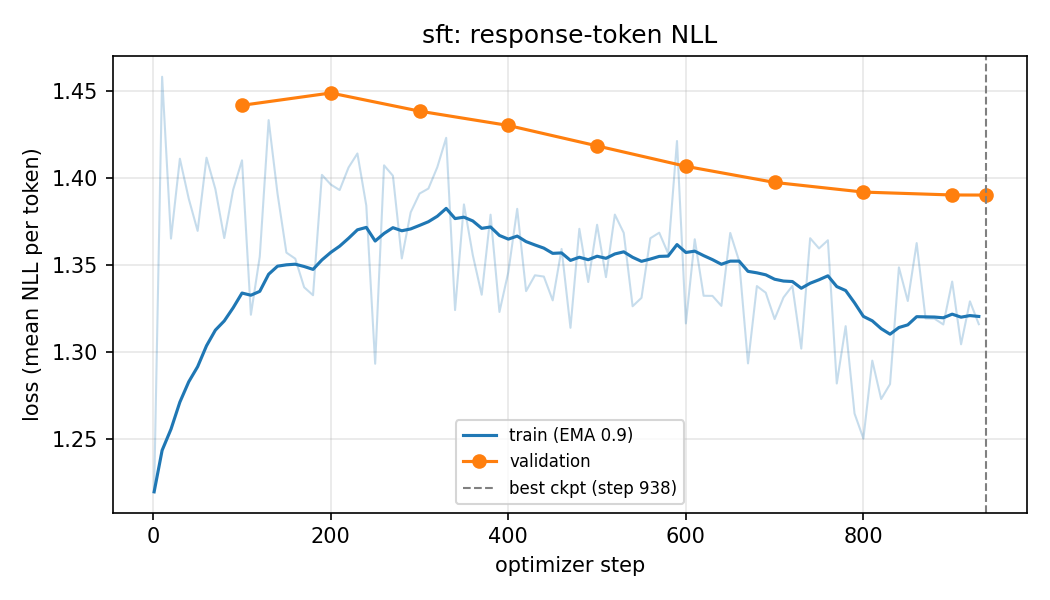

In [9]:
!cat outputs/sft/summary.json
sh("python scripts/plot_metrics.py --run sft=outputs/sft --out_dir outputs/plots")
from IPython.display import Image, display
display(Image("outputs/plots/sft_loss.png"))

In [10]:
!cd outputs && zip -q -r /kaggle/working/sft_run_outputs.zip sft -x "*.safetensors" "*.bin"
!ls -lh /kaggle/working/sft_run_outputs.zip && du -sh outputs/sft

-rw-r--r-- 1 root root 7.6M Oct 17 12:56 /kaggle/working/sft_run_outputs.zip
3.8G	outputs/sft


## Task 4 — From-scratch DPO run 1: HH-RLHF (`configs/dpo_hh.yaml`, §10.3–10.4)

Policy = SFT `best` (fp32, `cuda:0`); frozen reference = SFT `best` (fp16, `cuda:1`); β = 0.1; LR 1e-6 fixed;
batch 1 × accumulation 32. Best checkpoint = highest validation reward accuracy.

In [11]:
sh("python scripts/train_dpo.py --config configs/dpo_hh.yaml --set sft_checkpoint=outputs/sft/best")

$ python scripts/train_dpo.py --config configs/dpo_hh.yaml --set sft_checkpoint=outputs/sft/best
The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
[dpo] train=15000 val=1000 optimizer_steps=469 policy=cuda:0 reference=cuda:1
{"split": "val", "step": 0, "elapsed_s": 60.2, "loss": 0.6931932270526886, "pairs": 1000.0, "reward_chosen": 0.00035478870500810445, "reward_rejected": 0.0004311203544493765, "reward_margin": -7.633166038431227e-05, "reward_accuracy": 0.498, "is_best": 0.0}
/kaggle/working/cs5326-PA2-27100015/scripts/../src/pa2/dpo.py:208: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you shou

{
  "optimizer_steps": 469,
  "best_val_reward_accuracy": 0.635,
  "best_val_reward_margin": 0.23583041605353355,
  "skipped_fp16_steps": 3
}$ python scripts/plot_metrics.py --run dpo_hh=outputs/dpo_hh --out_dir outputs/plots
plotted dpo_hh


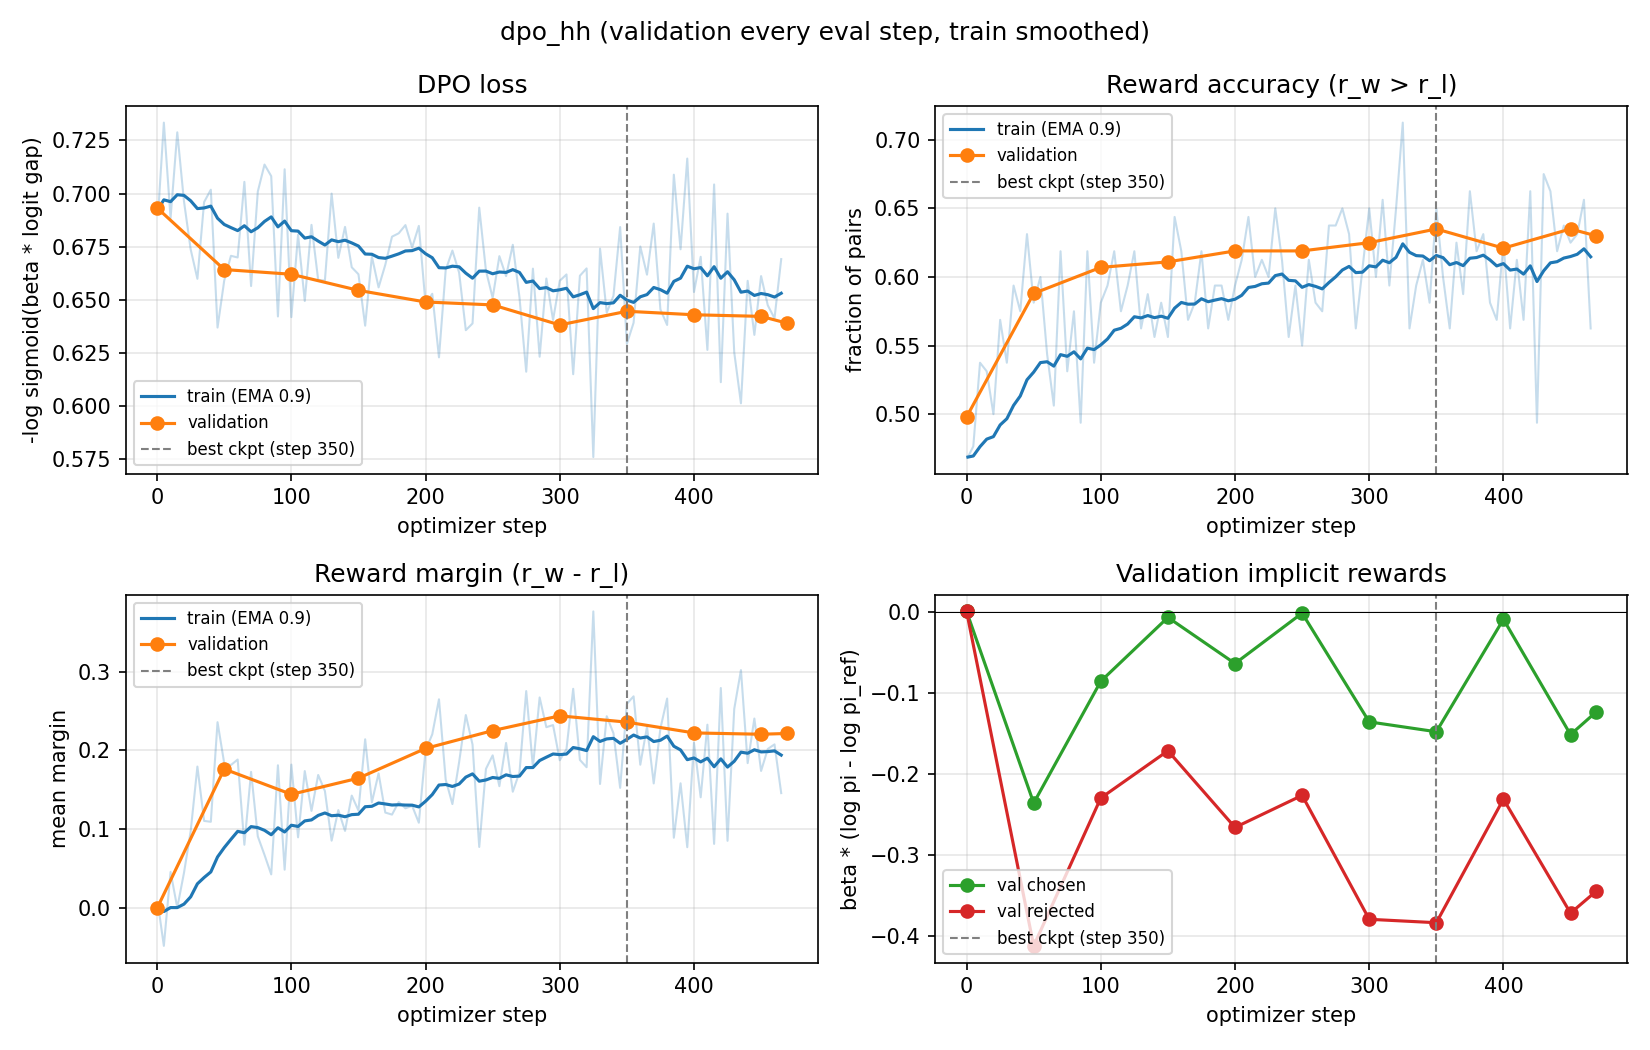

In [12]:
!cat outputs/dpo_hh/summary.json
sh("python scripts/plot_metrics.py --run dpo_hh=outputs/dpo_hh --out_dir outputs/plots")
from IPython.display import Image, display
display(Image("outputs/plots/dpo_hh_metrics.png"))

In [13]:
!cd outputs && zip -q -r /kaggle/working/dpo_hh_run_outputs.zip dpo_hh -x "*.safetensors" "*.bin"
!ls -lh /kaggle/working/dpo_hh_run_outputs.zip && du -sh outputs/dpo_hh

-rw-r--r-- 1 root root 7.6M Oct 17 14:35 /kaggle/working/dpo_hh_run_outputs.zip
3.8G	outputs/dpo_hh


## Task 4 — From-scratch DPO run 2: UltraFeedback (`configs/dpo_uf.yaml`, same code and settings)

In [14]:
sh("python scripts/train_dpo.py --config configs/dpo_uf.yaml --set sft_checkpoint=outputs/sft/best")

$ python scripts/train_dpo.py --config configs/dpo_uf.yaml --set sft_checkpoint=outputs/sft/best
The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
[dpo] train=15000 val=1000 optimizer_steps=469 policy=cuda:0 reference=cuda:1
{"split": "val", "step": 0, "elapsed_s": 137.2, "loss": 0.6932941765785218, "pairs": 1000.0, "reward_chosen": -2.3931457952130585e-05, "reward_rejected": 0.00023713568912353365, "reward_margin": -0.00026106718298979104, "reward_accuracy": 0.496, "is_best": 0.0}
/kaggle/working/cs5326-PA2-27100015/scripts/../src/pa2/dpo.py:208: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you 

{
  "optimizer_steps": 469,
  "best_val_reward_accuracy": 0.711,
  "best_val_reward_margin": 0.7669186076521873,
  "skipped_fp16_steps": 3
}$ python scripts/plot_metrics.py --run dpo_uf=outputs/dpo_uf --out_dir outputs/plots
plotted dpo_uf


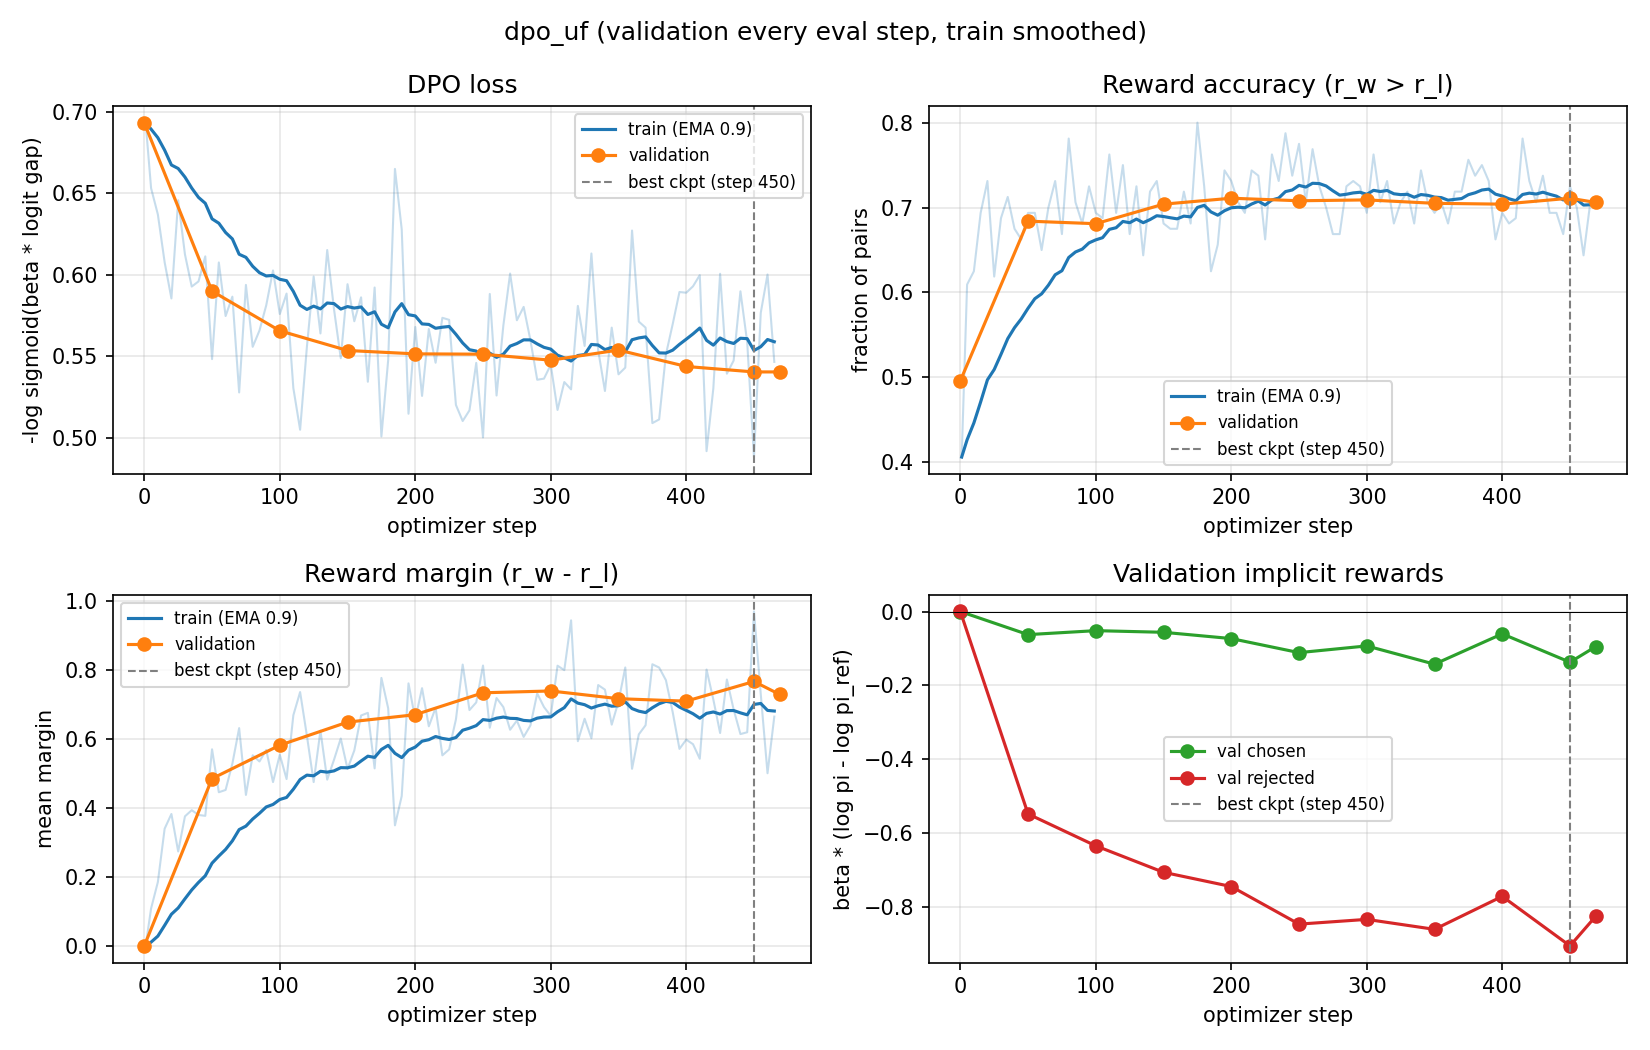

In [15]:
!cat outputs/dpo_uf/summary.json
sh("python scripts/plot_metrics.py --run dpo_uf=outputs/dpo_uf --out_dir outputs/plots")
from IPython.display import Image, display
display(Image("outputs/plots/dpo_uf_metrics.png"))

In [16]:
!cd outputs && zip -q -r /kaggle/working/dpo_uf_run_outputs.zip dpo_uf -x "*.safetensors" "*.bin"
!ls -lh /kaggle/working/dpo_uf_run_outputs.zip && du -sh outputs/dpo_uf

-rw-r--r-- 1 root root 7.6M Oct 17 16:44 /kaggle/working/dpo_uf_run_outputs.zip
3.8G	outputs/dpo_uf


## Task 5 — Idiot Sandwich: TRL DPOTrainer + LoRA (`configs/lora_dpo.yaml`)

`HuggingFaceTB/SmolLM2-360M-Instruct` on `data/persona_lora/ramsay_style_preferences.json` (22 rows held out).

In [17]:
sh("python scripts/train_lora_dpo.py --config configs/lora_dpo.yaml")

$ python scripts/train_lora_dpo.py --config configs/lora_dpo.yaml
`torch_dtype` is deprecated! Use `dtype` instead!

Tokenizing train dataset: 100%|██████████| 198/198 [00:00<00:00, 698.29 examples/s]

Tokenizing eval dataset: 100%|██████████| 22/22 [00:00<00:00, 690.18 examples/s]
[lora] train=198 val=22 trainable params=8,683,520 / 370,504,640

100%|██████████| 3/3 [00:00<00:00,  4.62it/s]

  3%|▎         | 2/75 [00:03<01:50,  1.51s/it]
                                              

  5%|▌         | 4/75 [00:05<01:31,  1.29s/it]
                                              

  8%|▊         | 6/75 [00:07<01:24,  1.22s/it]
                                              

 11%|█         | 8/75 [00:10<01:19,  1.18s/it]
                                              

 13%|█▎        | 10/75 [00:12<01:17,  1.19s/it]
                                               

 13%|█▎        | 10/75 [00:12<01:17,  1.19s/it]{'loss': 0.6931, 'grad_norm': 1.4257148504257202, 'learning_rate': 6.25e-06, 'en

{
  "initial_eval": {
    "eval_loss": 0.6931473016738892,
    "eval_model_preparation_time": 0.0205,
    "eval_runtime": 1.4205,
    "eval_samples_per_second": 15.487,
    "eval_steps_per_second": 2.112
  },
  "final_eval": {
    "eval_loss": 0.12692898511886597,
    "eval_model_preparation_time": 0.0205,
    "eval_runtime": 0.939,
    "eval_samples_per_second": 23.429,
    "eval_steps_per_second": 3.195
  }
}$ python scripts/plot_metrics.py --run lora_dpo=outputs/lora_dpo --out_dir outputs/plots
plotted lora_dpo


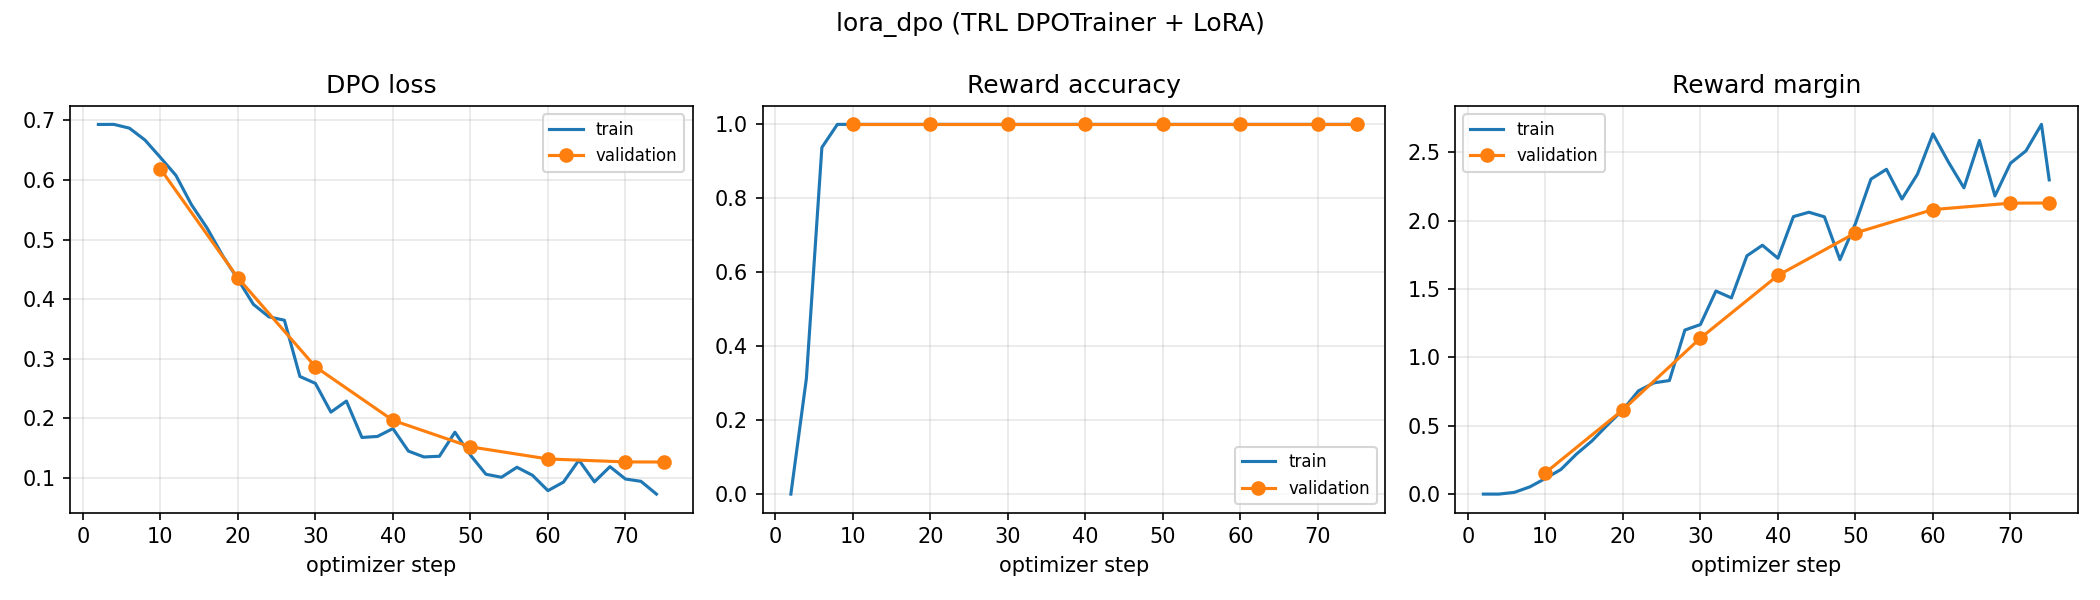

In [18]:
!cat outputs/lora_dpo/summary.json
sh("python scripts/plot_metrics.py --run lora_dpo=outputs/lora_dpo --out_dir outputs/plots")
from IPython.display import Image, display
display(Image("outputs/plots/lora_dpo_metrics.png"))

In [19]:
!cd outputs && zip -q -r /kaggle/working/lora_dpo_run_outputs.zip lora_dpo -x "*.safetensors" "*.bin"
!ls -lh /kaggle/working/lora_dpo_run_outputs.zip && du -sh outputs/lora_dpo

-rw-r--r-- 1 root root 1.2M Oct 17 16:47 /kaggle/working/lora_dpo_run_outputs.zip
38M	outputs/lora_dpo


## Training plots for the report (§14.4)

$ python scripts/plot_metrics.py --run sft=outputs/sft --run dpo_hh=outputs/dpo_hh --run dpo_uf=outputs/dpo_uf --run lora_dpo=outputs/lora_dpo --out_dir outputs/plots
plotted sft
plotted dpo_hh
plotted dpo_uf
plotted lora_dpo


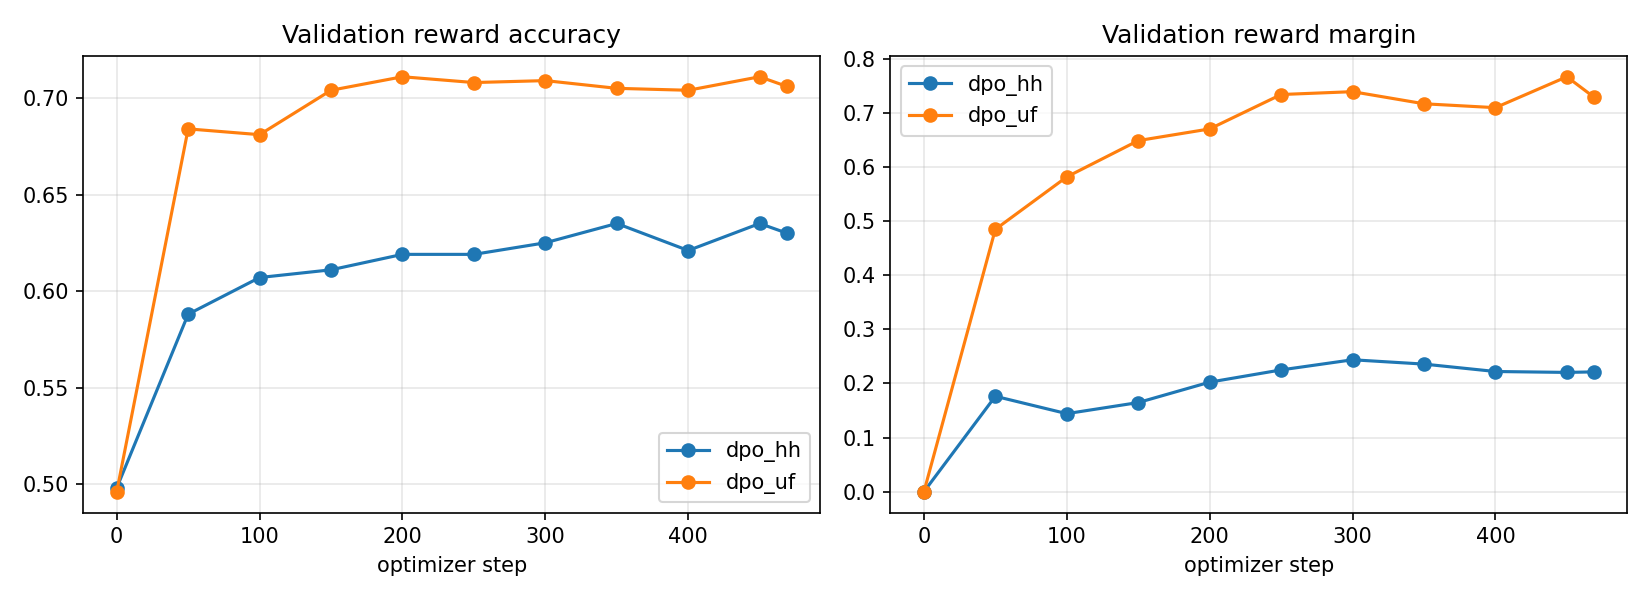

In [20]:
sh("python scripts/plot_metrics.py --run sft=outputs/sft --run dpo_hh=outputs/dpo_hh "
   "--run dpo_uf=outputs/dpo_uf --run lora_dpo=outputs/lora_dpo --out_dir outputs/plots")
!cd outputs && zip -q -r /kaggle/working/plots.zip plots
from IPython.display import Image, display
display(Image("outputs/plots/dpo_runs_comparison.png"))

**Done.** This version's outputs are the input dataset for Notebook 2 (generation).